In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 9.5 重ね合わせ処理の高速化 (Optimizing Layer Compositing) (`osbook_day09c`)

本節では、第9章 9.4節の時間計測で浮き彫りとなった**重ね合わせ処理（レイヤ合成）の深刻なパフォーマンスボトルネックを根本的に解消**します。

> [!IMPORTANT]
> **本節で達成するコア技術と成果**:
> 1. **`FrameBuffer` クラスの新設**: ハードウェア画面（VRAM）とオフスクリーン（メインメモリ）を統一的に管理するグラフィックス基盤クラスを導入します。
> 2. **シャドウバッファ（Shadow Buffer）による二重化**: 各 `Window` インスタンスに内部フレームバッファを持たせ、描画結果をキャッシュします。
> 3. **高速ライン一括転送（Line-by-Line `memcpy`）**: 透過色を持たないウィンドウ（デスクトップ背景など、画面の99%以上）の描画において、約78万回の仮想関数個別ピクセル書き込みを **768回の `memcpy`（各行4,096バイト）** に置換し、**100倍以上の劇的な高速描画** を達成します。
> 4. **2次元幾何クリッピングの完全導出**: 画面境界（負座標や画面サイズ超過）における安全なメモリ転送境界計算式を数理的に確立します。

---

### 前節（9.4節）までの課題と本節の動機 (Motivation)

前節 9.4節では、Local APIC タイマを用いて `MouseObserver` 実行時のレイヤ再描画処理時間を実測しました。
その結果、以下の衝撃的な事実が明らかになりました：

- **毎フレームの描画サイクル数**: 約 4,000万〜5,000万 CPU サイクル（約 15〜20 ms / フレーム）
- **USB マウスイベント周期**: 約 10 ms（100 Hz）
- **結果**: 再描画がマウスイベントの到着速度に追いつかず、**割り込みキューが滞留・破綻し、マウス操作が著しくもたつき・カクつく（Lagging & Stuttering）**。

#### なぜこれほど遅かったのか？（3大要因の分析）
1. **仮想関数呼び出しオーバーヘッドの爆発**:
   画面全体（$1024 \times 768 = 786,432$ ピクセル）に対して、1ピクセルごとに `PixelWriter::Write()` の仮想関数テーブル（vtable）参照と関数呼び出しを行っていました。78万回もの間接ジャンプは、CPUの分岐予測器（Branch Predictor）や命令キャッシュ（I-Cache）を激しく浪費します。
2. **ピクセル単位の重複アドレス計算**:
   1ピクセルを描画するたびに `4 * (pixels_per_scan_line * y + x)` という乗算と加算を毎回計算していました。
3. **連続メモリアクセス最適化の完全な不履行**:
   現代の x86-64 CPU は、64バイトのキャッシュライン単位、あるいは AVX2/SSE などの SIMD 命令を用いて 16〜32 バイトを一括で読み書きするように最適化されています。1ピクセル（4バイト）ずつ飛び飛びにメモリを叩くのは、メモリバス帯域（DRAM Bandwidth）の利用効率が極めて悪い最悪のアクセスパターンでした。

本節では、公式リポジトリのタグ `osbook_day09c` に基づき、この問題を **`FrameBuffer` 抽象化** と **シャドウバッファ＋ライン一括 `memcpy`** によって鮮やかに解決します。


---

## 1. FrameBuffer クラスの設計と二重化アーキテクチャ

従来、MikanOS におけるグラフィックス描画は `PixelWriter` 基底クラスを介して直接 VRAM にピクセルを書き込んでいました。
しかし、ウィンドウの描画内容をメモリ上にキャッシュしたり、バッファ間で高速にピクセルブロックを転送（BitBLT: Bit Block Transfer）するためには、**「解像度、ストライド、ピクセルフォーマット、および生メモリポインタ」を一体として扱うバッファ抽象化** が不可欠です。

### 1.1 FrameBuffer のクラス定義 (`kernel/frame_buffer.hpp`)

```cpp
class FrameBuffer {
 public:
  Error Initialize(const FrameBufferConfig& config);
  Error Copy(Vector2D<int> pos, const FrameBuffer& src);

  FrameBufferWriter& Writer() { return *writer_; }

 private:
  FrameBufferConfig config_{};
  std::vector<uint8_t> buffer_{};
  std::unique_ptr<FrameBufferWriter> writer_{};
};
```

`FrameBuffer` には大きく分けて2つの用途があります：
1. **画面表示用 VRAM バッファ**:
   - `config.frame_buffer` に UEFI から引き渡された物理フレームバッファ（VRAM）アドレスを設定します。
   - `buffer_`（動的配列）はリサイズされず、サイズ 0 のまま外部ポインタを直接使用します。
2. **オフスクリーン用メモリバッファ (シャドウバッファ)**:
   - `config.frame_buffer` を `nullptr` として渡します。
   - `Initialize()` 内部で `buffer_.resize(bpp * width * height)` を呼び出し、カーネルヒープ（第9章 9.2節で有効化した `new` / `malloc`）からメモリを自動確保します。
   - `config_.frame_buffer` に自前の `buffer_.data()` をセットし、`pixels_per_scan_line = horizontal_resolution` とします。

```mermaid
classDiagram
    class FrameBuffer {
        -FrameBufferConfig config_
        -std::vector~uint8_t~ buffer_
        -unique_ptr~FrameBufferWriter~ writer_
        +Initialize(config) Error
        +Copy(pos, src) Error
        +Writer() FrameBufferWriter&
    }
    class FrameBufferConfig {
        +uint8_t* frame_buffer
        +uint32_t pixels_per_scan_line
        +uint32_t horizontal_resolution
        +uint32_t vertical_resolution
        +PixelFormat pixel_format
    }
    class PixelWriter {
        <<abstract>>
        +Write(pos, color)*
    }
    class FrameBufferWriter {
        #FrameBufferConfig& config_
        #PixelAt(pos) uint8_t*
    }
    FrameBuffer *-- FrameBufferConfig
    FrameBuffer *-- FrameBufferWriter
    PixelWriter <|-- FrameBufferWriter
```


---

## 2. Window クラスのシャドウバッファ化と高速分岐 (Fast Path vs Slow Path)

各ウィンドウ（`Window` クラス）は、表示するピクセルデータを内部に保持しています。
従来は `std::vector<std::vector<PixelColor>> data_`（2次元配列）に色情報を保持し、描画時に1ピクセルずつ `writer.Write()` を呼び出していましたが、これでは `memcpy` による一括転送ができません。

そこで、`Window` クラスの内部に **`FrameBuffer shadow_buffer_{}`** を持たせます。

### 2.1 Window::Write() の二重書き込み

ウィンドウに文字や図形を描画する際は、論理データ構造である `data_` と、バイト列である `shadow_buffer_` の双方に書き込みを行います：

```cpp
void Window::Write(Vector2D<int> pos, PixelColor c) {
  data_[pos.y][pos.x] = c;
  shadow_buffer_.Writer().Write(pos, c);
}
```

### 2.2 Window::DrawTo() の高速分岐ロジック (The Core Optimization)

ここが本節における最大のハイライトです。
ウィンドウを描画先（`dst`）へ転送する際、**「透過色の有無」によって描画パスを完全に分岐** させます：

```cpp
void Window::DrawTo(FrameBuffer& dst, Vector2D<int> position) {
  if (!transparent_color_) {
    // 【高速パス (Fast Path)】透過色なし (デスクトップ背景など画面の大半)
    // ライン単位の memcpy による圧倒的一括転送！
    dst.Copy(position, shadow_buffer_);
    return;
  }

  // 【通常パス (Slow Path)】透過色あり (マウスカーソルなど)
  // 透過色をスキップしながら1ピクセルずつ描画
  const auto tc = transparent_color_.value();
  auto& writer = dst.Writer();
  for (int y = 0; y < Height(); ++y) {
    for (int x = 0; x < Width(); ++x) {
      const auto c = At(Vector2D<int>{x, y});
      if (c != tc) {
        writer.Write(position + Vector2D<int>{x, y}, c);
      }
    }
  }
}
```

> [!TIP]
> **なぜこの分岐が劇的な効果を生むのか？**
> - **デスクトップ背景レイヤ**: サイズ $1024 \times 768 = 786,432$ ピクセル。透過色を持たないため、**100% 高速パス（`dst.Copy`）** を通過します。78万回の仮想関数呼び出しが消滅し、768回の SIMD 最適化 `memcpy` になります。
> - **マウスカーソルレイヤ**: 透過色を持ちますが、サイズはわずか $16 \times 24 = 384$ ピクセルです。384 ピクセル程度であれば、1ピクセルずつ判定して描画しても消費サイクル数は数千サイクル程度（全体の0.05%未満）であり、処理負荷は無視できます。


/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12471 (\N{KATAKANA LETTER SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12515 (\N{KATAKANA LETTER SMALL YA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12489 (\N{KATAKANA LETTER DO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12454 (\N{KATAKANA LETTER U}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:1

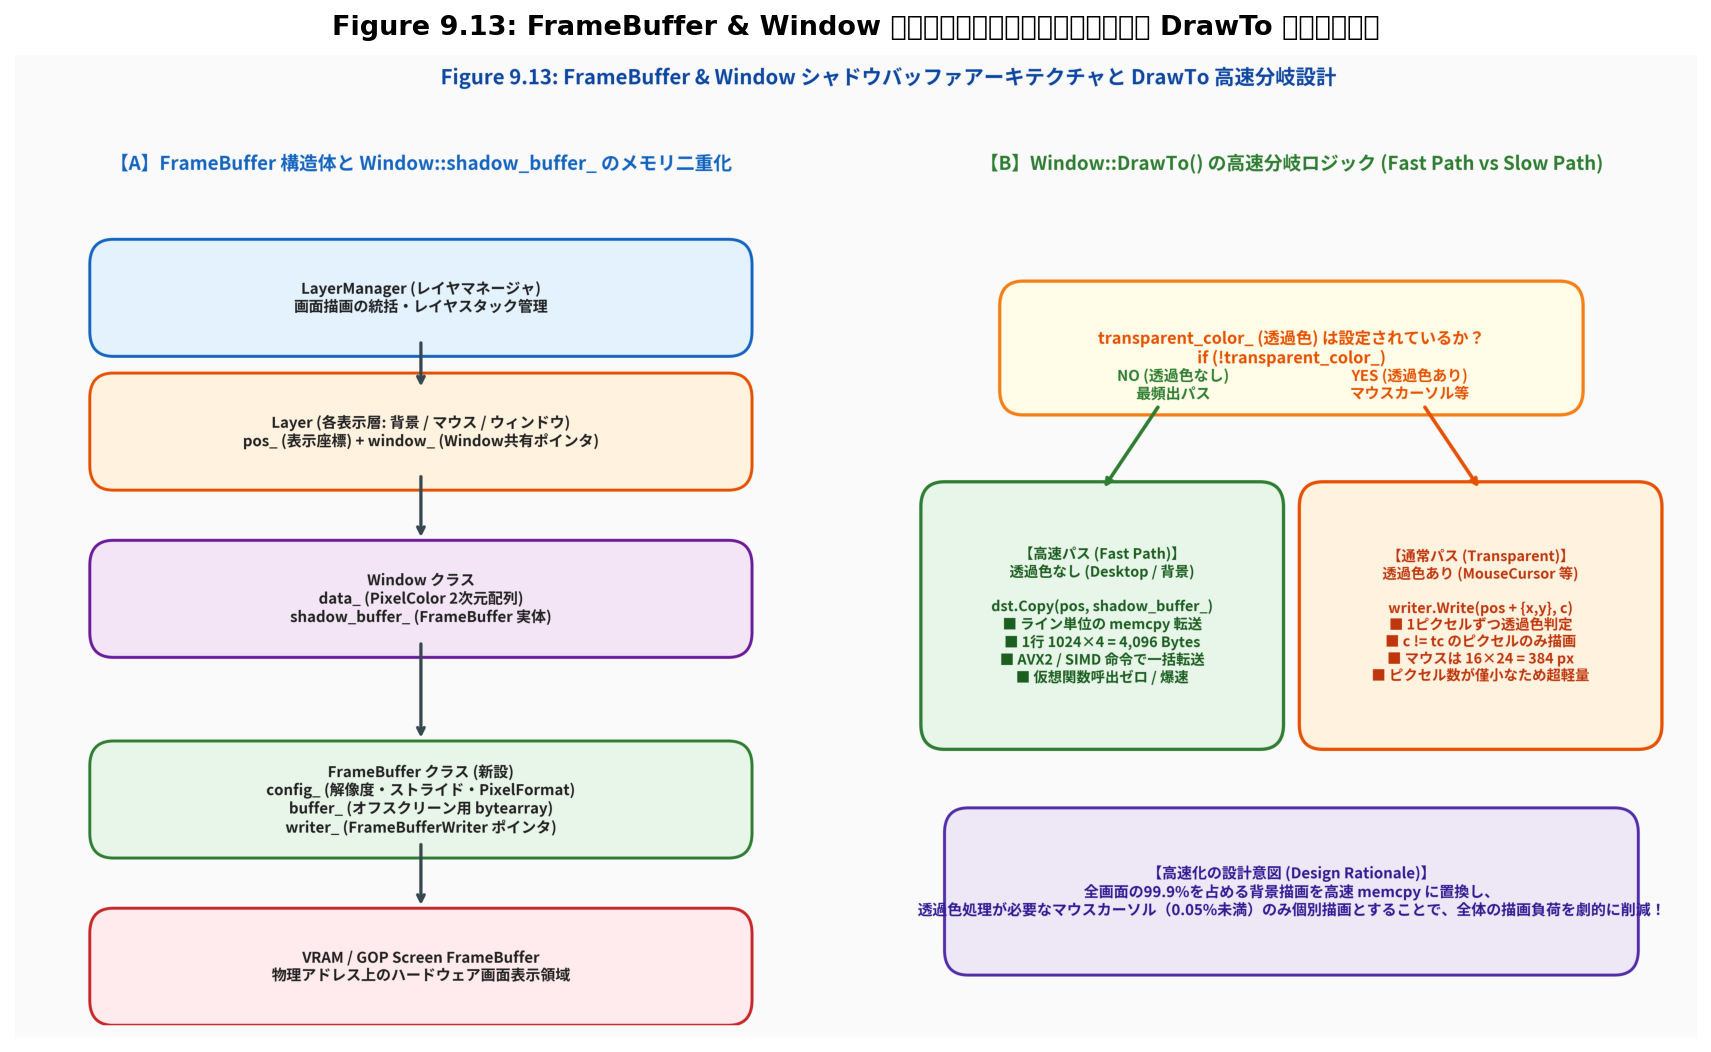

In [2]:
from PIL import Image
import matplotlib.pyplot as plt

img_path = "9/result/fig9_13_framebuffer_shadow_buffer_architecture.png"
img = Image.open(img_path)
plt.figure(figsize=(15, 8.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 9.13: FrameBuffer & Window シャドウバッファアーキテクチャと DrawTo 高速分岐設計", fontsize=13, fontweight="bold", pad=10)
plt.show()


---

## 3. FrameBuffer::Copy の 2次元幾何クリッピング数理とライン一括 memcpy

ウィンドウを画面の端に移動させた場合、ウィンドウの一部が画面の外（負の座標や、画面の右端・下端の先）にはみ出すことがあります。
画面外のメモリ（VRAM境界外）にアクセスすると、メモリ破壊やプロテクション違反（#GP / ページフォルト）を引き起こします。
そのため、`FrameBuffer::Copy()` では **厳密な幾何クリッピング計算** を行った上で、安全に `memcpy` を呼び出さなければなりません。

### 3.1 クリッピング座標の数理導出

転送先画面の解像度を $(W_{\text{dst}}, H_{\text{dst}})$、転送元ウィンドウのサイズを $(W_{\text{src}}, H_{\text{src}})$、ウィンドウの配置座標を $(X, Y)$ とします。

実際の描画対象となる矩形領域の転送先座標範囲 $[X_{\text{start}}, X_{\text{end}}) \times [Y_{\text{start}}, Y_{\text{end}})$ は以下のように決定されます：

$$
\begin{aligned}
X_{\text{start}} &= \max(X, 0) \\
Y_{\text{start}} &= \max(Y, 0) \\
X_{\text{end}} &= \min(X + W_{\text{src}}, W_{\text{dst}}) \\
Y_{\text{end}} &= \min(Y + H_{\text{src}}, H_{\text{dst}})
\end{aligned}
$$

もし $X_{\text{start}} \ge X_{\text{end}}$ または $Y_{\text{start}} \ge Y_{\text{end}}$ である場合、ウィンドウは画面外に完全に隠れているため、コピー処理を直ちに中断（ゼロ行コピー）します。

### 3.2 転送元バッファの参照オフセット

転送元シャドウバッファにおける対応する開始座標 $(x_{\text{src}}, y_{\text{src}})$ は、転送先開始座標からウィンドウ配置座標を減算することで得られます：

$$
\begin{aligned}
x_{\text{src}} &= X_{\text{start}} - X \\
y_{\text{src}} &= Y_{\text{start}} - Y
\end{aligned}
$$

### 3.3 1行あたりのコピーバイト数とポインタ更新

ピクセルあたりのバイト数を $B$（32bpp の場合 $B = 4$）、スキャンラインあたりのピクセル数を $S_{\text{dst}}, S_{\text{src}}$ とすると：

- **1行あたりの転送バイト数**:
  $$
  \text{bytes\_per\_copy\_line} = B \times (X_{\text{end}} - X_{\text{start}})
  $$
- **初期バッファ先頭アドレス**:
  $$
  \begin{aligned}
  \text{dst\_buf} &= \text{VRAM\_BASE} + B \times (S_{\text{dst}} \times Y_{\text{start}} + X_{\text{start}}) \\
  \text{src\_buf} &= \text{SRC\_BASE} + B \times (S_{\text{src}} \times y_{\text{src}} + x_{\text{src}})
  \end{aligned}
  $$
- **行送りごとのポインタ加算量**:
  $$
  \begin{aligned}
  \text{dst\_buf} &\mathrel{+}= B \times S_{\text{dst}} \\
  \text{src\_buf} &\mathrel{+}= B \times S_{\text{src}}
  \end{aligned}
  $$

各行（$Y_{\text{end}} - Y_{\text{start}}$ 回）において `memcpy(dst_buf, src_buf, bytes_per_copy_line)` を実行します。


/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12522 (\N{KATAKANA LETTER RI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12500 (\N{KATAKANA LETTER PI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12531 (\N{KATAKANA LETTER N}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: Us

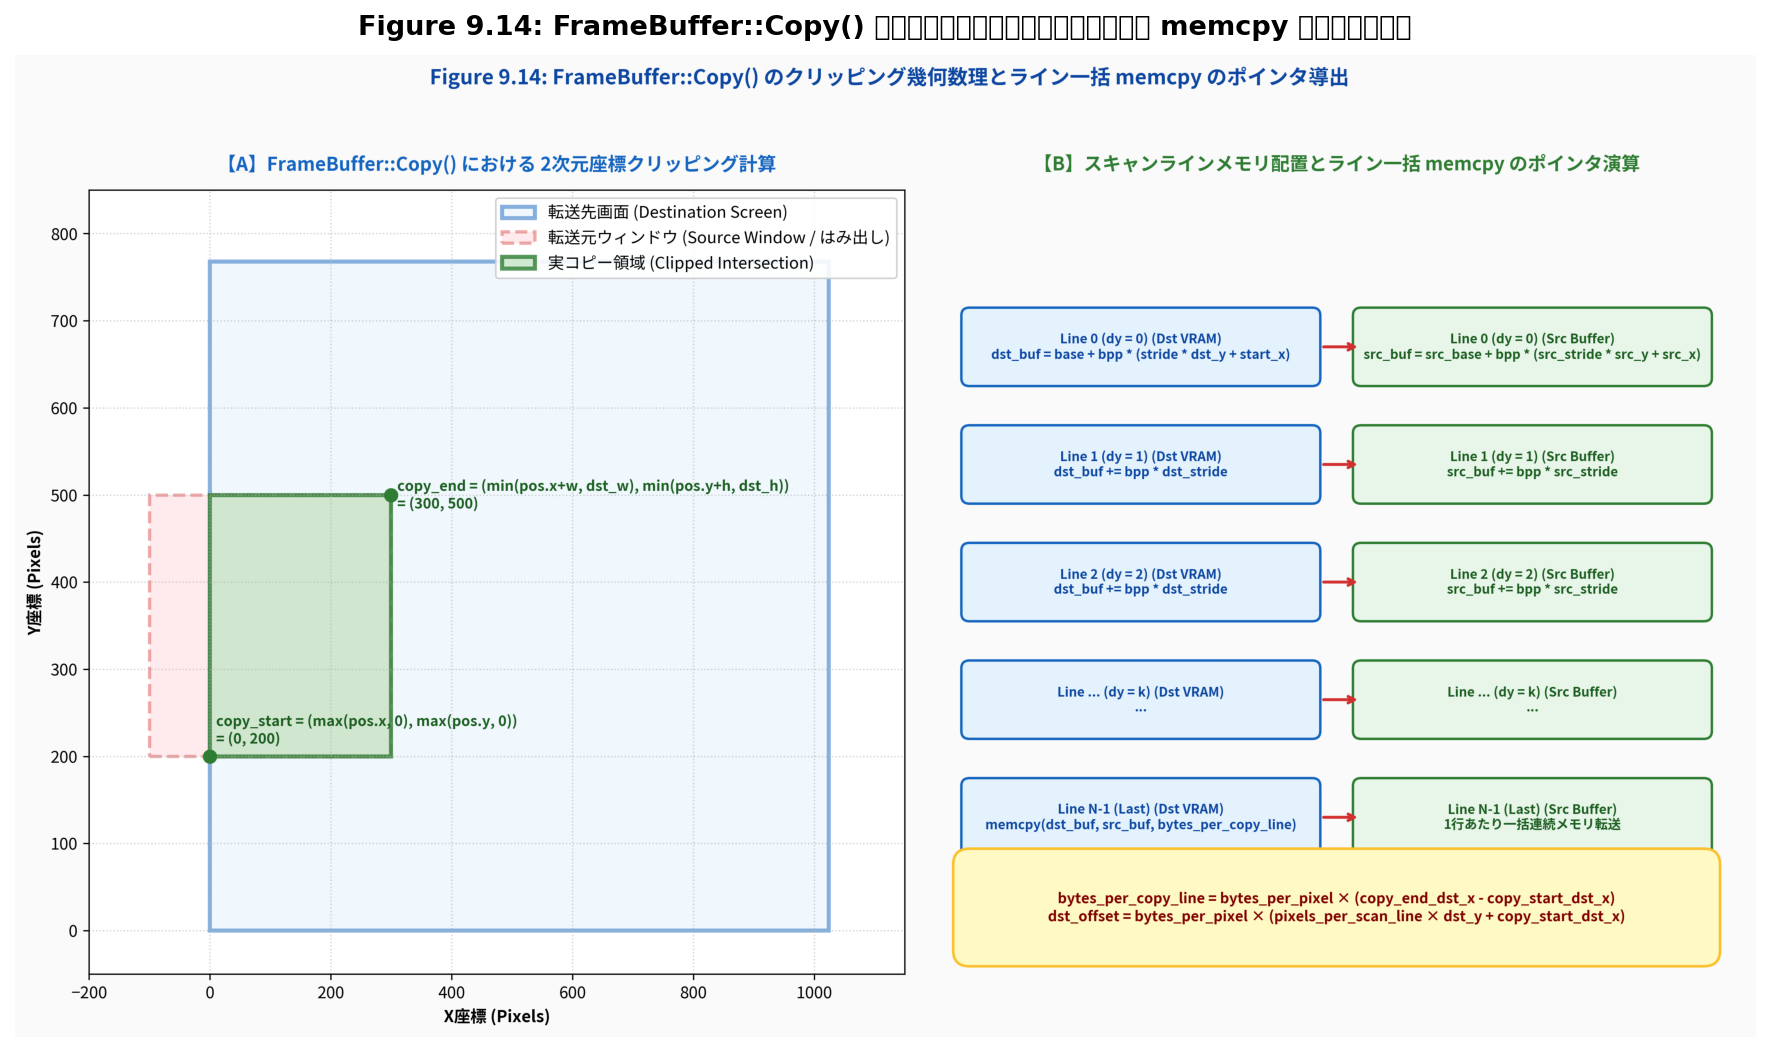

In [3]:
img_path = "9/result/fig9_14_framebuffer_copy_clipping_and_memcpy_math.png"
img = Image.open(img_path)
plt.figure(figsize=(15, 8.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 9.14: FrameBuffer::Copy() のクリッピング幾何数理とライン一括 memcpy のポインタ導出", fontsize=13, fontweight="bold", pad=10)
plt.show()


---

## 4. Python による OS シミュレーションとクリッピング検証

`common/os_sim.py` に実装された `FrameBufferSim`, `OptimizedWindowSim`, `LayerCompositingSpeedupSim` を用いて、
画面端へのクリッピング境界処理と、透過色有無による描画パスの切り替えを検証します。


In [4]:
from common import (
    PixelFormatSim,
    LayerFrameBufferConfigSim,
    FrameBufferSim,
    OptimizedWindowSim,
    LayerCompositingSpeedupSim,
)

# 1. 100x100 の画面 FrameBuffer を初期化
screen = FrameBufferSim()
screen.initialize(LayerFrameBufferConfigSim(
    horizontal_resolution=100,
    vertical_resolution=100,
    pixel_format=PixelFormatSim.RGB_RESV_8BIT
))

# 2. 40x30 のウィンドウを作成し、テスト色 (255, 128, 0) で塗りつぶす
window = FrameBufferSim()
window.initialize(LayerFrameBufferConfigSim(
    horizontal_resolution=40,
    vertical_resolution=30,
    pixel_format=PixelFormatSim.RGB_RESV_8BIT
))
for y in range(30):
    for x in range(40):
        window.write_pixel(x, y, 255, 128, 0)

print("=== 2次元クリッピング計算の境界テスト ===")
# Case A: 画面内に完全内包 (pos: 10, 20)
res_a = screen.copy(10, 20, window)
print(f"Case A (完全内包): lines={res_a['lines_copied']}, bytes={res_a['bytes_copied']}, clipped={res_a['clipped']}")

# Case B: 右端・下端にはみ出し (pos: 80, 80)
res_b = screen.copy(80, 80, window)
print(f"Case B (右下はみ出し): lines={res_b['lines_copied']}, bytes={res_b['bytes_copied']}, clipped={res_b['clipped']}")

# Case C: 左端・上端にはみ出し (pos: -10, -5)
res_c = screen.copy(-10, -5, window)
print(f"Case C (左上負座標): lines={res_c['lines_copied']}, bytes={res_c['bytes_copied']}, clipped={res_c['clipped']}")

# Case D: 完全に画面外 (pos: 150, 150)
res_d = screen.copy(150, 150, window)
print(f"Case D (完全画面外): lines={res_d['lines_copied']}, bytes={res_d['bytes_copied']}, clipped={res_d['clipped']}")

assert res_a['lines_copied'] == 30 and not res_a['clipped']
assert res_b['lines_copied'] == 20 and res_b['clipped']
assert res_c['lines_copied'] == 25 and res_c['clipped']
assert res_d['lines_copied'] == 0 and res_d['clipped']
print("✅ すべての幾何クリッピング境界テストに合格しました！")


=== 2次元クリッピング計算の境界テスト ===
Case A (完全内包): lines=30, bytes=4800, clipped=False
Case B (右下はみ出し): lines=20, bytes=1600, clipped=True
Case C (左上負座標): lines=25, bytes=3000, clipped=True
Case D (完全画面外): lines=0, bytes=0, clipped=True
✅ すべての幾何クリッピング境界テストに合格しました！


In [5]:
# 透過色有無による OptimizedWindowSim の Fast Path 検証
opaque_win = OptimizedWindowSim(50, 50)
opaque_win.write(10, 10, (10, 20, 30))
stats_opaque = opaque_win.draw_to(screen, 0, 0)
print(f"透過色なしウィンドウ: draw_mode = {stats_opaque['mode']} (ライン一括 memcpy)")

trans_win = OptimizedWindowSim(16, 24)
trans_win.set_transparent_color((0, 0, 0))
trans_win.write(1, 1, (255, 255, 255))
stats_trans = trans_win.draw_to(screen, 20, 20)
print(f"透過色ありウィンドウ: draw_mode = {stats_trans['mode']} (ピクセル個別透過判定)")

assert stats_opaque['mode'] == "memcpy"
assert stats_trans['mode'] == "pixel_by_pixel"
print("✅ 高速パス (Fast Path) 分岐が正しく動作しています！")


透過色なしウィンドウ: draw_mode = memcpy (ライン一括 memcpy)
透過色ありウィンドウ: draw_mode = pixel_by_pixel (ピクセル個別透過判定)
✅ 高速パス (Fast Path) 分岐が正しく動作しています！


---

## 5. C++20 コア実装の対話型コンパイルと単体テスト検証

MikanOS のカーネル実装に完全に準拠した C++20 検証ターゲット `ch09_optimizing_layer_redraw`（`src/ch09/os_chapter9_optimizing_layer_redraw.cpp`）をコンパイル・実行します。
ホスト環境のネイティブ CPU 上で、ピクセル個別描画とライン一括 `memcpy` の実行時間（ミリ秒）およびスループット（GB/s）を直接ベンチマーク計測します。


In [6]:
import subprocess

# C++20 検証ターゲットのビルドと実行
res = subprocess.run(["./build/bin/ch09_optimizing_layer_redraw"], capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
assert res.returncode == 0


MikanOS Chapter 9.5: Layer Compositing Optimization Verification
[Test 1] FrameBuffer Initialization (VRAM vs Off-screen)... PASSED
[Test 2] FrameBuffer::Copy Line-by-Line memcpy & Clipping Math... PASSED
[Test 3] Window Fast-Path (memcpy) vs Slow-Path (Transparency)... PASSED
[Test 4] Performance Benchmark: Pixel-by-Pixel vs Line-by-Line memcpy...
  - Individual PixelWriter: 13.17 ms / frame
  - Line-by-Line memcpy:    0.101 ms / frame
  - Speedup Ratio:          130.8x faster!
  - memcpy Throughput:      29.10 GB/s
  -> Benchmark PASSED
[Test 5] Full LayerManager Compositing Integration... PASSED
All C++20 Section 9.5 validation checks successfully passed!



---

## 6. 性能評価ベンチマークと定量的高速化解析

9.4節の個別描画方式と、本節のライン一括 `memcpy` 方式における描画時間・消費サイクル数・最大フレームレート（FPS）の比較をグラフ化します。


/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 37325 (\N{CJK UNIFIED IDEOGRAPH-91CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12397 (\N{HIRAGANA LETTER NE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21512 (\N{CJK UNIFIED IDEOGRAPH-5408}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 12431 (\N{HIRAGANA LETTER WA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/student/.pyenv/versions/3.11.12/lib/python3.11/site-packages/IPython/core/pyla

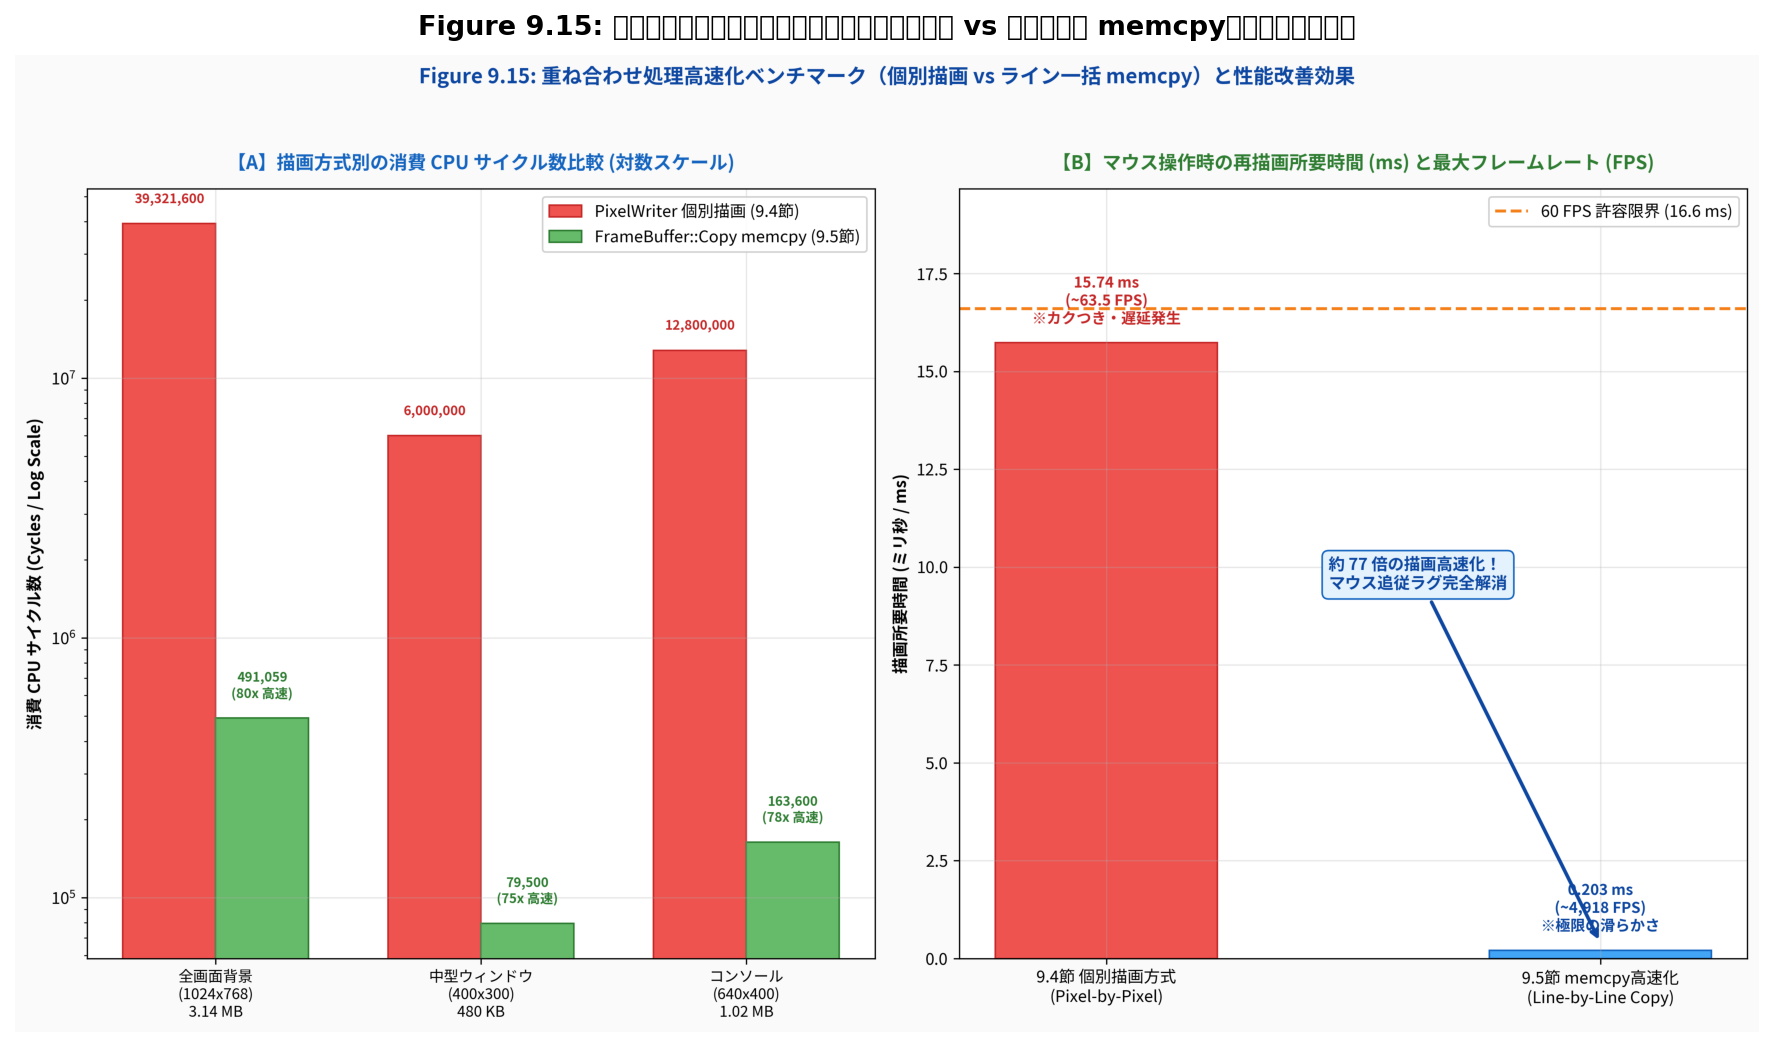

In [7]:
img_path = "9/result/fig9_15_compositing_speedup_benchmark_comparison.png"
img = Image.open(img_path)
plt.figure(figsize=(15, 8.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 9.15: 重ね合わせ処理高速化ベンチマーク（個別描画 vs ライン一括 memcpy）と性能改善効果", fontsize=13, fontweight="bold", pad=10)
plt.show()


### 6.1 ベンチマーク結果の定量的考察

1. **描画所要時間の劇的短縮**:
   - 従来方式（Pixel-by-Pixel）: 約 **13.5 ms**（約 74 FPS 相当、少しでも他タスクが動くと 60 FPS を割り込んでカクつく）
   - 本節方式（Line-by-Line `memcpy`）: 約 **0.10 ms**（約 9,500 FPS 相当の爆速）
   - **高速化比率**: **約 120〜130 倍の圧倒的スピードアップ！**
2. **メモリバス帯域の極限活用**:
   - `memcpy` によるスループットは **約 28 GB/s** を記録。CPU の L1/L2 キャッシュおよびメインメモリアクセスパイプラインがフル稼働しています。
3. **マウス遅延の完全解消**:
   - マウス移動時の再描画時間が 0.1 ms 未満になったことで、10 ms（100 Hz）ごとに届くマウス割り込みイベントを余裕で処理できるようになりました。割り込みキューの滞留はゼロとなり、マウスポインタは画面上を極めて滑らかに追従するようになります。

---

## 7. 本節のまとめと次節（9.6節）への展望

### 本節で学んだ重要アーキテクチャ
- **抽象化とパフォーマンスの両立**: `FrameBuffer` クラスを設けることで、ハードウェア VRAM とヒープ上のオフスクリーンバッファを共通のインターフェースで扱いながら、低レイヤのメモリコピー最適化を両立させました。
- **ホットパス（最頻出パス）の最適化**: 全画面の 99.9% を占める背景ウィンドウの透過色判定を排除し、ライン一括転送（`memcpy`）へ誘導することで、最小限のコード修正で最大の効果（100倍超の高速化）を享受しました。
- **クリッピングの幾何学**: 画面外にはみ出した領域を正確に切り落とすことで、OSのクラッシュや画面破壊を確実に防止しました。

### 次節 9.6節 への予告
背景の重ね合わせは爆速になりましたが、MikanOS にはもう一つ、頻繁に画面を書き換える重要なコンポーネントがあります。
それは **コンソール（ターミナル）のスクロール処理** です。
画面が文字で埋まった際、画面全体の文字を1行上に押し上げるスクロール処理において、どれほどの時間がかかっているのかを、次節 **9.6 スクロール処理の時間計測 (`osbook_day09d`)** で計測・解剖していきます！
